# Intro

* How to create and train a classifier LM to categorize writing styles
* How to smooth time series with a mean-smoothing filter

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import requests

import torch
import torch.nn as nn

from transformers import BertModel, BertTokenizer

In [2]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
tokenizer

BertTokenizer(name_or_path='bert-base-uncased', vocab_size=30522, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})

# Import the Two Datasets

In [3]:
# Alice in Wonderland
text = requests.get('https://www.gutenberg.org/cache/epub/11/pg11/txt').text
alice_tokens = torch.tensor(tokenizer.encode(text), dtype=torch.long)

# Edgar Allan Poe
text = requests.get('https://www.gutenberg.org/cache/epub/2148/pg2148.txt').text
edgar_tokens = torch.tensor(tokenizer.encode(text), dtype=torch.long)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (2354 > 512). Running this sequence through the model will result in indexing errors


# Create an LLM model using pretrained BERT with a new head

In [4]:
class BertForBinaryClassification(nn.Module):
  def __init__(self, num_labels=2):
    super(BertForBinaryClassification, self).__init__()

    # Load the pretrained BERT model
    self.bert = BertModel.from_pretrained('bert-base-uncased')

    # classification head that converts the 768-d pooled output into 2 final outputs
    self.classifier = nn.Linear(768,2)
    self.dropout    = nn.Dropout(.1) # hard-coded dropout at 10%

    # initialize the weights and biases
    nn.init.xavier_uniform_(self.classifier.weight)
    nn.init.zeros_(self.classifier.bias)

  def forward(self, input_ids, attention_mask=None, token_type_ids=None):

    # forward pass through the downloaded (pretrained) BERT
    outputs = self.bert(
        input_ids = input_ids,
        attention_mask = attention_mask,
        token_type_ids = token_type_ids,
    )

    # extract the pooled output and apply dropout
    pooled_output = self.dropout(outputs.pooler_output)


    # final push through the classification layer
    logits = self.classifier(pooled_output)
    return logits

In [5]:
model = BertForBinaryClassification().to(device)
model

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertForBinaryClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, e

# Prepare to fine-tune the model

In [6]:
# training hyperparameters
num_training = 150
batch_size   = 32
seq_len      = 256

# optimizer and loss function
optimizer = torch.optim.AdamW(model.parameters(), lr = 5e-7)
loss_fun = nn.CrossEntropyLoss()

In [7]:
# create a batch of data
ix_alice = torch.randint(len(alice_tokens)-seq_len,size=(batch_size//2,))
ix_edgar = torch.randint(len(edgar_tokens)-seq_len,size=(batch_size//2,))
X = torch.concatenate(
    (alice_tokens[ix_alice[:,None] + torch.arange(seq_len)],
     edgar_tokens[ix_edgar[:,None] + torch.arange(seq_len)]), axis = 0
).to(device)

labels = torch.concatenate((
    torch.zeros(batch_size//2,dtype=torch.long),
    torch.ones(batch_size//2,dtype=torch.long)),
                           axis=0
).to(device)

print(f'Data batch shape:   {X.shape}')
print(f'Labels batch shape: {labels.shape}')

# forward pass, get model predictions and report the loss + acc
logits = model(X)
pred_labels = torch.argmax(logits, dim = 1)
loss = loss_fun(logits, labels).item()

print('\nPredicted labels:\n', pred_labels)
print('Actual labels:\n', labels)

print(f'\nLoss: {loss:.4f}')
print(f'\nAccuracy: {(pred_labels == labels).sum().item()/batch_size}')

Data batch shape:   torch.Size([32, 256])
Labels batch shape: torch.Size([32])

Predicted labels:
 tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0], device='cuda:0')
Actual labels:
 tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1], device='cuda:0')

Loss: 0.8968

Accuracy: 0.4375


# Train the Model

In [8]:
losses   = np.zeros(num_training)
accuracy = np.zeros(num_training)

for sampli in range(num_training):

    ix_alice = torch.randint(len(alice_tokens)-seq_len, size=(batch_size//2,))
    ix_edgar = torch.randint(len(edgar_tokens)-seq_len, size=(batch_size//2,))

    X = torch.concatenate((
        alice_tokens[ix_alice[:, None] + torch.arange(seq_len)],
        edgar_tokens[ix_edgar[:, None] + torch.arange(seq_len)]
    ), axis=0).to(device)

    # forward
    y_hat = model(X)

    # loss
    loss = loss_fun(y_hat, labels)
    losses[sampli] = loss.item()

    # accuracy
    preds = torch.argmax(y_hat, dim=1)
    accuracy[sampli] = (preds == labels).float().mean().item()

    # backward
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if sampli % 7 == 0:
        print(f"Sample {sampli:4}/{num_training}, loss: {losses[sampli]:.2f}, accuracy: {accuracy[sampli]:.2f}")

Sample    0/150, loss: 0.89, accuracy: 0.41
Sample    7/150, loss: 0.76, accuracy: 0.53
Sample   14/150, loss: 0.76, accuracy: 0.50
Sample   21/150, loss: 0.70, accuracy: 0.56
Sample   28/150, loss: 0.61, accuracy: 0.59
Sample   35/150, loss: 0.49, accuracy: 0.72
Sample   42/150, loss: 0.50, accuracy: 0.66
Sample   49/150, loss: 0.50, accuracy: 0.75
Sample   56/150, loss: 0.49, accuracy: 0.75
Sample   63/150, loss: 0.36, accuracy: 0.94
Sample   70/150, loss: 0.35, accuracy: 0.97
Sample   77/150, loss: 0.34, accuracy: 0.94
Sample   84/150, loss: 0.33, accuracy: 0.88
Sample   91/150, loss: 0.30, accuracy: 1.00
Sample   98/150, loss: 0.28, accuracy: 0.97
Sample  105/150, loss: 0.24, accuracy: 1.00
Sample  112/150, loss: 0.20, accuracy: 1.00
Sample  119/150, loss: 0.22, accuracy: 1.00
Sample  126/150, loss: 0.17, accuracy: 1.00
Sample  133/150, loss: 0.16, accuracy: 1.00
Sample  140/150, loss: 0.18, accuracy: 1.00
Sample  147/150, loss: 0.17, accuracy: 1.00


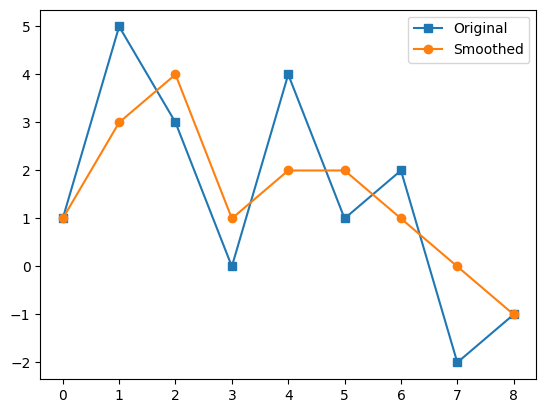

In [9]:
# mean smoothing function
def meansmoothing(x, k=3):
  y = x+0 # copy of the data
  w = (k-1)//2 # number of elements to average on either side

  # loop over samples
  for i in range(w, len(x)-w):
    y[i] = x[i-w:i+w].mean() # centered mean

  return y

# demo

x = np.array([1,5,3,0,4,1,2,-2,-1])
y = meansmoothing(x)
plt.plot(x, 's-', label='Original')
plt.plot(y, 'o-', label='Smoothed')
plt.legend()

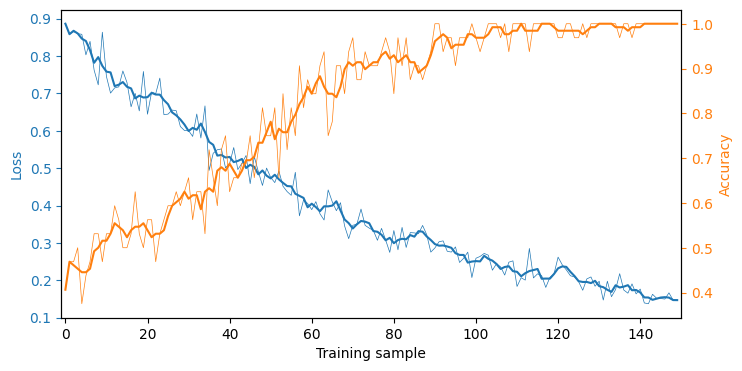

In [10]:
_, ax = plt.subplots(1, figsize=(8,4))

# plot the losses
ax.plot(losses, 'C0', linewidth=.5)
ax.plot(meansmoothing(losses,5), 'C0')
ax.set_ylabel('Loss', color='C0')
ax.tick_params(axis='y', color='C0', labelcolor='C0')

axr = ax.twinx()
axr.plot(accuracy, 'C1', linewidth=.5)
axr.plot(meansmoothing(accuracy,5), 'C1')
axr.set_ylabel('Accuracy', color='C1')
axr.tick_params(axis='y', color='C1', labelcolor='C1')

ax.set(xlabel='Training sample', xlim=[-1,num_training])
plt.show()

# Save Model

In [11]:
torch.save(model.state_dict(), 'bert_classifier_AliceVsEdgar.pt')